# Práctica A: ¿Puede la IA predecir el clima? Benchmark Punchana (SENAMHI Iquitos)

Este notebook implementa el caso de estudio **Caso A**:
- Evaluación rigurosa sobre **2,557 días** reales de la estación meteorológica Punchana (Loreto, Perú).
- Split temporal ciego de **90 días de holdout** (Octubre a Diciembre 2025).
- Comparativa de 8 modelos: Naive estacional, ARIMA, Holt-Winters, Random Forest, ExtraTrees, LSTM, Chronos Zero-Shot (Amazon) y TimesFM Zero-Shot (Google).
- Prueba formal de significancia estadística de **Diebold-Mariano** y regla de parsimonia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar benchmark consolidado de 8 modelos
df_bm = pd.read_csv('../data/benchmark_punchana.csv')
print('=== BENCHMARK DE 8 MODELOS (HOLDOUT 90 DÍAS) ===')
df_bm

=== BENCHMARK DE 8 MODELOS (HOLDOUT 90 DÍAS) ===


,modelo,familia,rmse_1d,mae_1d,rmse_7d,mae_7d,tiempo_s,hardware,cobertura_p10_p90,p_valor_vs_mejor
0,ExtraTrees (Geurts 06),Machine Learning (Árboles),1.880,1.466,2.983,2.536,0.11,CPU,NaN,1.0000
1,Random Forest,Machine Learning (Árboles),1.885,1.471,3.549,3.017,0.23,CPU,NaN,0.9181
2,"ARIMA (2,0,1)",Estadístico Clásico,1.964,1.506,2.062,1.582,0.96,CPU,NaN,0.1510
3,TimesFM (Google) Zero-Shot,Foundation Model,1.965,1.392,4.086,3.350,7.87,GPU (CUDA),66.7%,0.2747
4,LSTM Deep Learning,Deep Learning Local,2.054,1.554,2.260,1.709,1.44,GPU (CUDA),NaN,0.0295
5,Holt-Winters Amortiguado,Estadístico Clásico,2.065,1.540,2.230,1.664,1.47,CPU,NaN,0.0426
6,Chronos (Amazon) Zero-Shot,Foundation Model,2.143,1.603,4.929,4.041,3.13,GPU (CUDA),73.3%,0.0126
7,Naive Estacional,Baseline Clásico,2.874,2.234,5.094,5.094,0.00,CPU,NaN,0.0001


## 2. Visualización Comparativa del Benchmark
Observemos cómo ExtraTrees, Random Forest, ARIMA y TimesFM empatan estadísticamente (p > 0.05), mientras que los baselines y LSTM pierden significativamente.

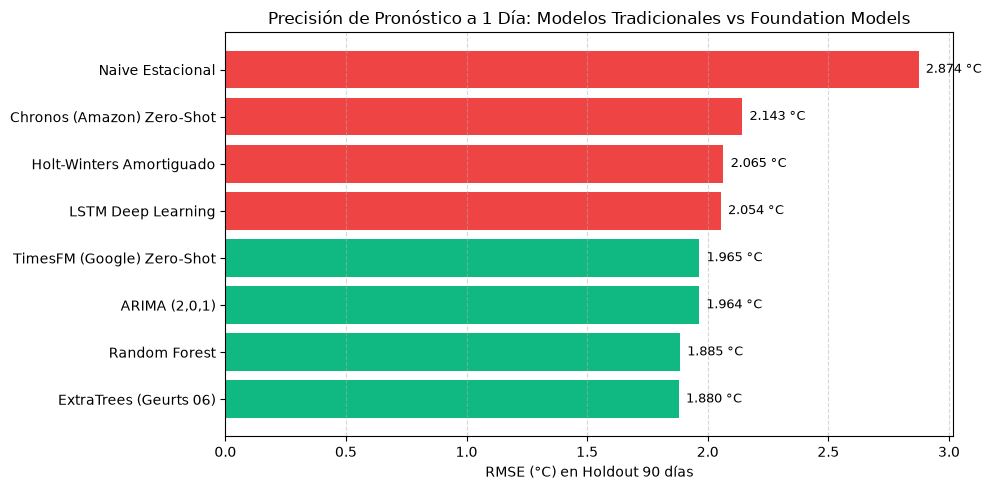

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#10b981' if p > 0.05 else '#f59e0b' if p == 1.0 else '#ef4444' for p in df_bm['p_valor_vs_mejor']]
bars = ax.barh(df_bm['modelo'], df_bm['rmse_1d'], color=colors)
ax.set_xlabel('RMSE (°C) en Holdout 90 días')
ax.set_title('Precisión de Pronóstico a 1 Día: Modelos Tradicionales vs Foundation Models')
ax.grid(axis='x', linestyle='--', alpha=0.5)
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.03, bar.get_y() + bar.get_height()/2, f'{width:.3f} °C', va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 3. Pronóstico Multi-Modelo a 7 Días con Bandas de Incertidumbre P10/P90

In [3]:
df_fc = pd.read_csv('../data/senamhi_forecast_7d.csv')
print('Pronóstico a 7 días:')
df_fc

Pronóstico a 7 días:


,fecha,tmax_observada,pred_extratrees,pred_chronos,pred_timesfm,pred_arima,ci_lower_p10,ci_upper_p90,chronos_p10,chronos_p90
0,2025-12-25,33.6,34.56,35.69,34.82,30.38,31.46,37.65,34.23,35.95
1,2025-12-26,33.2,33.04,35.21,34.54,30.38,29.95,36.13,33.53,36.17
2,2025-12-27,32.4,32.99,35.45,34.36,30.38,29.90,36.09,33.96,36.41
3,2025-12-28,27.2,32.73,34.97,34.21,30.38,29.64,35.82,33.29,35.93
4,2025-12-29,30.4,32.55,34.97,34.12,30.38,29.45,35.64,33.27,36.17
5,2025-12-30,27.8,32.61,34.97,34.00,30.38,29.52,35.70,32.55,36.17
6,2025-12-31,31.0,32.64,35.45,33.90,30.38,29.55,35.73,33.05,36.17


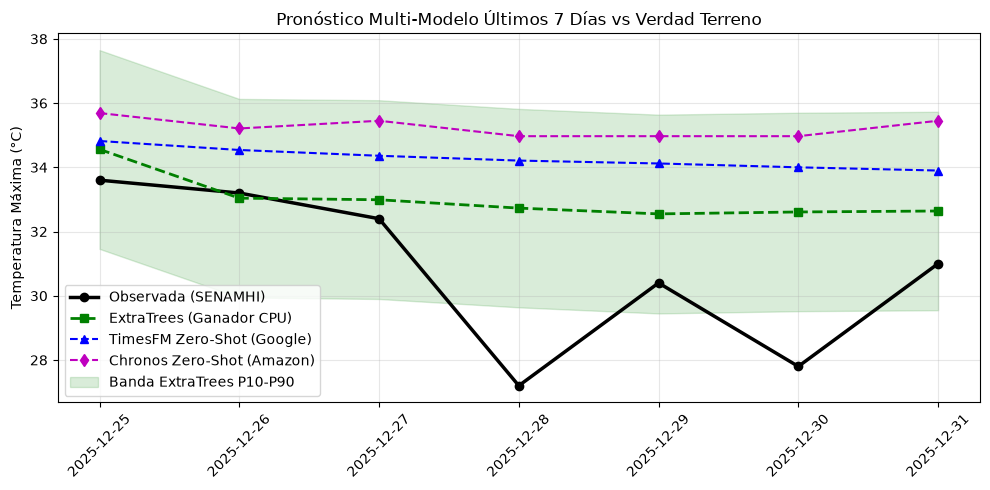

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(df_fc['fecha'], df_fc['tmax_observada'], 'k-o', label='Observada (SENAMHI)', linewidth=2.5)
plt.plot(df_fc['fecha'], df_fc['pred_extratrees'], 'g--s', label='ExtraTrees (Ganador CPU)', linewidth=2)
plt.plot(df_fc['fecha'], df_fc['pred_timesfm'], 'b--^', label='TimesFM Zero-Shot (Google)', linewidth=1.5)
plt.plot(df_fc['fecha'], df_fc['pred_chronos'], 'm--d', label='Chronos Zero-Shot (Amazon)', linewidth=1.5)
plt.fill_between(df_fc['fecha'], df_fc['ci_lower_p10'], df_fc['ci_upper_p90'], color='green', alpha=0.15, label='Banda ExtraTrees P10-P90')
plt.title('Pronóstico Multi-Modelo Últimos 7 Días vs Verdad Terreno')
plt.ylabel('Temperatura Máxima (°C)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()